# Bài 12: Học Chuyển giao (Transfer Learning) và Tinh chỉnh Mô hình (Fine-Tuning)

## 1. Mục tiêu học tập
- Nắm vững bản đồ tiến hóa các kiến trúc phân loại ảnh hiện đại: `LeNet` → `AlexNet` → `VGG` → `Inception` → `ResNet` → `DenseNet` → `MobileNet` → `EfficientNet` → `ConvNeXt`.
- Phân biệt rạch ròi 4 chế độ làm việc với mô hình:
  1. **Pretrained Inference (Chỉ suy luận bằng trọng số có sẵn)**: Không huấn luyện, không cập nhật trọng số.
  2. **Training from Scratch (Huấn luyện từ đầu)**: Khởi tạo ngẫu nhiên toàn bộ mạng, tốn nhiều dữ liệu và thời gian.
  3. **Feature Extraction / Linear Probing (Trích xuất đặc trưng)**: Đóng băng (`freeze`, `requires_grad=False`) toàn bộ phần thân mạng (`backbone`), chỉ huấn luyện tầng phân loại cuối (`head`).
  4. **Fine-Tuning (Tinh chỉnh)**: Mở khóa (`unfreeze`) thêm các tầng sâu của `backbone` và huấn luyện với tốc độ học phân tầng (**Differential Learning Rates**: `lr` rất nhỏ cho `backbone`, `lr` lớn hơn cho `head`).
- Thực hành huấn luyện thật cả 3 chiến lược (`Scratch` vs `Feature Extraction` vs `Fine-Tuning`) trên tập dữ liệu mục tiêu nhỏ, kèm hướng dẫn sử dụng `torchvision.models` cả khi có Internet lẫn khi Offline hoàn toàn.

## 2. Kiến thức cần có
- Đã hoàn thành Bài 10 và Bài 11.

## 3. Thời gian học dự kiến
- Khoảng **2.0 – 2.5 giờ** (ước tính).

## 4. Bài toán thực tế đơn giản
Trong thực tế, bạn thường chỉ thu thập được `20 – 50` bức ảnh cho mỗi loại sản phẩm mới. Nếu huấn luyện một mạng CNN lớn từ con số 0 (`Training from scratch`) trên `80` ảnh, mạng sẽ học vẹt (`overfit`) ngay lập tức. Nhờ **Transfer Learning**, ta tận dụng bộ lọc cạnh, góc, hình khối mà mạng đã học từ một tập dữ liệu nguồn lớn hơn, giúp đạt độ chính xác cao chỉ sau vài epoch!

## 5. Giải thích trực quan: Cấu trúc Backbone + Head và Chiến lược Đóng băng (`Freeze`)
```
[Ảnh đầu vào (3, H, W)]
          │
          ▼
┌───────────────────────────────────────────────────────────┐
│ BACKBONE (Thân mạng trích xuất đặc trưng: Stem + Stages)  │
│  - Stage 1 (Tầng nông): Bắt cạnh, góc, màu sắc tổng quát  │──► Luôn giữ cố định (requires_grad=False)
│  - Stage 2 (Tầng giữa): Bắt họa tiết, kết cấu hình học    │──► Đóng băng ở pha 1, mở khóa nhẹ ở pha 2
│  - Stage 3 (Tầng sâu) : Bắt bộ phận vật thể đặc thù       │──► Mở khóa với lr nhỏ (ví dụ 2e-4) khi Fine-tune
└───────────────────────────────────────────────────────────┘
          │ Vector đặc trưng (Embedding)
          ▼
┌───────────────────────────────────────────────────────────┐
│ CLASSIFICATION HEAD (Tầng Linear mới thay thế cho C lớp)  │──► Luôn cập nhật với lr chuẩn (ví dụ 2e-3)
└───────────────────────────────────────────────────────────┘
```

## 6 & 7. Thuật ngữ mới, Tham số & Công thức Tốc độ học Phân tầng
| Keyword | Nghĩa tiếng Việt | Nhóm | Vai trò & Lưu ý lỗi thường gặp |
|---|---|---|---|
| `backbone` | Khung xương sống trích xuất đặc trưng | Kiến trúc | Toàn bộ mạng CNN/ViT trừ tầng phân loại cuối cùng (`fc` hoặc `classifier`). |
| `head` | Đầu dự đoán tác vụ | Kiến trúc | Tầng `nn.Linear(in_features, num_target_classes)` mới khởi tạo để khớp với số lớp của bài toán mới. |
| `freeze / unfreeze` | Đóng băng / Mở khóa tham số | Huấn luyện | Đặt `p.requires_grad = False` (freeze) hoặc `True` (unfreeze). **Lưu ý**: Với tầng `BatchNorm2d` trong phần đóng băng, nếu tập mới quá nhỏ, nên giữ tầng đó ở chế độ `.eval()` để không làm lệch `running_mean/var`. |
| `param_groups` (Differential LR) | Nhóm tham số có `lr` khác nhau | Tối ưu hóa | Truyền danh sách dict vào optimizer: `[{"params": backbone_params, "lr": 1e-4}, {"params": head_params, "lr": 1e-3}]`. |


In [1]:
# Cell 1: Chuẩn bị Mô hình Nguồn (Pretrained Backbone) & Hướng dẫn Torchvision Online/Offline
import sys
from pathlib import Path

current_dir = Path.cwd().resolve()
project_root = current_dir.parent if current_dir.name == "notebooks" else current_dir
if (project_root / "image_ai_learning").is_dir():
    project_root = project_root / "image_ai_learning"
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.models import resnet18
from sklearn.model_selection import train_test_split

from src.utils import set_seed, get_device, count_parameters, save_checkpoint
from src.synthetic_data import generate_synthetic_shapes_dataset
from src.models import ResidualCNN
from src.training import fit_classifier, evaluate_classifier

QUICK_RUN = True
set_seed(42)
device = get_device()

# Minh họa cách khởi tạo ResNet-18 từ torchvision:
# - Khi có Internet: dùng resnet18(weights=ResNet18_Weights.DEFAULT) để tải trọng số ImageNet (~44.7 MB).
# - Khi Offline: dùng weights=None rồi nạp từ file local checkpoint (.pt) bằng load_state_dict().
torchvision_r18_demo = resnet18(weights=None)
torchvision_r18_demo.fc = nn.Linear(torchvision_r18_demo.fc.in_features, 4)  # Thay head 1000 lớp bằng 4 lớp
print("Torchvision ResNet-18 (thay head 4 lớp) -> Tổng tham số:", count_parameters(torchvision_r18_demo)["total"])

# Để bài thực hành chạy nhanh 100% offline trên CPU, ta huấn luyện trước một ResidualCNN trên tập nguồn (Source Task)
# làm "Pretrained Source Model", sau đó chuyển giao sang tập mục tiêu cực nhỏ (Target Few-Shot Task)!
src_ds = generate_synthetic_shapes_dataset(num_samples=240, image_size=32, seed=10, noise_std=6.0)
X_src = torch.from_numpy(src_ds["images"]).permute(0, 3, 1, 2).float() / 255.0
y_src = torch.from_numpy(src_ds["labels"]).long()
src_mean = X_src.mean(dim=(0, 2, 3), keepdim=True)
src_std = X_src.std(dim=(0, 2, 3), keepdim=True) + 1e-6
X_src_norm = (X_src - src_mean) / src_std

src_loader = DataLoader(TensorDataset(X_src_norm, y_src), batch_size=32, shuffle=True)
pretrained_source_model = ResidualCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
opt_src = torch.optim.AdamW(pretrained_source_model.parameters(), lr=3e-3, weight_decay=1e-4)
crit = nn.CrossEntropyLoss()

for _ in range(10 if QUICK_RUN else 20):
    pretrained_source_model.train()
    for xb, yb in src_loader:
        opt_src.zero_grad()
        loss = crit(pretrained_source_model(xb.to(device)), yb.to(device))
        loss.backward()
        opt_src.step()

pretrained_backbone_state = copy.deepcopy(pretrained_source_model.state_dict())
print("Đã chuẩn bị xong trọng số Pretrained Backbone từ miền dữ liệu nguồn!")


Torchvision ResNet-18 (thay head 4 lớp) -> Tổng tham số: 11178564
Đã chuẩn bị xong trọng số Pretrained Backbone từ miền dữ liệu nguồn!


In [2]:
# Cell 2: Tạo Tập dữ liệu Mục tiêu Nhỏ (Target Domain có nhiễu mạnh & dịch màu, chỉ có 64 ảnh Train)
target_ds = generate_synthetic_shapes_dataset(num_samples=160, image_size=32, seed=99, noise_std=22.0)
# Đảo kênh màu để tạo sự dịch chuyển miền (domain shift) giữa miền nguồn và miền đích
target_imgs = target_ds["images"][:, :, :, ::-1].copy()
target_labels = target_ds["labels"]
class_names = target_ds["class_names"]

idx_all = np.arange(len(target_imgs))
idx_tr, idx_temp = train_test_split(idx_all, test_size=0.60, random_state=42, stratify=target_labels)  # Chỉ 40% (~64 ảnh) cho Train!
idx_va, idx_te = train_test_split(idx_temp, test_size=0.50, random_state=42, stratify=target_labels[idx_temp])

X_tgt = torch.from_numpy(target_imgs).permute(0, 3, 1, 2).float() / 255.0
y_tgt = torch.from_numpy(target_labels).long()
X_tgt_norm = (X_tgt - src_mean) / src_std  # Chuẩn hóa theo thống kê của mô hình Pretrained!

tr_loader = DataLoader(TensorDataset(X_tgt_norm[idx_tr], y_tgt[idx_tr]), batch_size=16, shuffle=True)
va_loader = DataLoader(TensorDataset(X_tgt_norm[idx_va], y_tgt[idx_va]), batch_size=32, shuffle=False)
te_loader = DataLoader(TensorDataset(X_tgt_norm[idx_te], y_tgt[idx_te]), batch_size=32, shuffle=False)
print(f"Tập dữ liệu mục tiêu ít mẫu -> Train: {len(idx_tr)} ảnh, Val: {len(idx_va)} ảnh, Test: {len(idx_te)} ảnh")


Tập dữ liệu mục tiêu ít mẫu -> Train: 64 ảnh, Val: 48 ảnh, Test: 48 ảnh


In [3]:
# Cell 3: Thực nghiệm So sánh 3 Chiến lược: (1) Train from Scratch vs (2) Feature Extraction vs (3) Fine-Tuning
epochs_cmp = 10 if QUICK_RUN else 20

# --- Chiến lược 1: Training from Scratch (Khởi tạo ngẫu nhiên toàn bộ) ---
set_seed(42)
model_scratch = ResidualCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
opt_scratch = torch.optim.AdamW(model_scratch.parameters(), lr=2e-3, weight_decay=1e-4)
hist_scratch = fit_classifier(model_scratch, tr_loader, va_loader, crit, opt_scratch, device, epochs=epochs_cmp)
_, _, pred_scr, _ = evaluate_classifier(model_scratch, te_loader, crit, device)
acc_scratch = float((pred_scr == target_labels[idx_te]).mean())

# --- Chiến lược 2: Feature Extraction (Nạp Pretrained, đóng băng toàn bộ Backbone, chỉ train tầng fc) ---
set_seed(42)
model_fe = ResidualCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
model_fe.load_state_dict(pretrained_backbone_state)
model_fe.fc = nn.Linear(64, 4).to(device)  # Khởi tạo lại tầng Head mới
for name, param in model_fe.named_parameters():
    param.requires_grad = name.startswith("fc.")

print("Tham số ở chế độ Feature Extraction:", count_parameters(model_fe))
opt_fe = torch.optim.AdamW([p for p in model_fe.parameters() if p.requires_grad], lr=3e-3, weight_decay=1e-4)
hist_fe = fit_classifier(model_fe, tr_loader, va_loader, crit, opt_fe, device, epochs=epochs_cmp)
_, _, pred_fe, _ = evaluate_classifier(model_fe, te_loader, crit, device)
acc_fe = float((pred_fe == target_labels[idx_te]).mean())

# --- Chiến lược 3: Fine-Tuning với Differential Learning Rate (Mở khóa stage3 + fc) ---
set_seed(42)
model_ft = ResidualCNN(in_channels=3, num_classes=4, base_channels=16).to(device)
model_ft.load_state_dict(pretrained_backbone_state)
model_ft.fc = nn.Linear(64, 4).to(device)
for name, param in model_ft.named_parameters():
    param.requires_grad = name.startswith("stage3.") or name.startswith("fc.")

opt_ft = torch.optim.AdamW(
    [
        {"params": model_ft.stage3.parameters(), "lr": 4e-4},  # LR nhỏ cho tầng sâu của backbone
        {"params": model_ft.fc.parameters(), "lr": 3e-3},      # LR lớn hơn cho tầng head mới
    ],
    weight_decay=1e-4,
)
ckpt_ft = project_root / "outputs" / "checkpoints" / "nb12_transfer_finetuned.pt"
hist_ft = fit_classifier(
    model_ft, tr_loader, va_loader, crit, opt_ft, device,
    epochs=epochs_cmp, checkpoint_path=ckpt_ft, class_names=class_names,
    preprocessing_config={"mean": src_mean.squeeze().tolist(), "std": src_std.squeeze().tolist()},
)
_, _, pred_ft, _ = evaluate_classifier(model_ft, te_loader, crit, device)
acc_ft = float((pred_ft == target_labels[idx_te]).mean())

print("\n=== KẾT QUẢ SO SÁNH 3 CHIẾN LƯỢC TRÊN TẬP TEST ÍT MẪU ===")
print(f"1. Training from Scratch : Test Accuracy = {acc_scratch*100:5.1f}% (100% tham số cập nhật)")
print(f"2. Feature Extraction    : Test Accuracy = {acc_fe*100:5.1f}% (Chỉ cập nhật 260 tham số của Head!)")
print(f"3. Fine-Tuning (Stage3+FC): Test Accuracy = {acc_ft*100:5.1f}% (Tốc độ học phân tầng)")


Tham số ở chế độ Feature Extraction: {'total': 77652, 'trainable': 260, 'frozen': 77392}

=== KẾT QUẢ SO SÁNH 3 CHIẾN LƯỢC TRÊN TẬP TEST ÍT MẪU ===
1. Training from Scratch : Test Accuracy =  31.2% (100% tham số cập nhật)
2. Feature Extraction    : Test Accuracy =  85.4% (Chỉ cập nhật 260 tham số của Head!)
3. Fine-Tuning (Stage3+FC): Test Accuracy =  81.2% (Tốc độ học phân tầng)


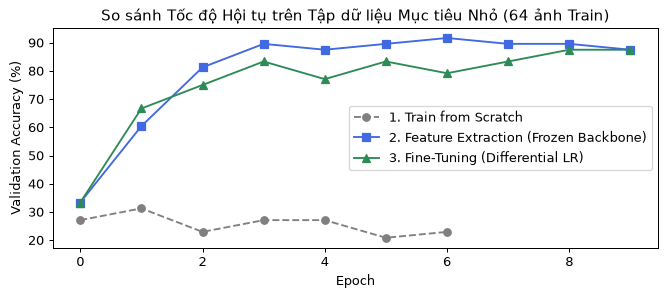

In [4]:
# Cell 4: Biểu đồ So sánh Tốc độ Hội tụ Validation Accuracy giữa 3 Chiến lược
plt.figure(figsize=(7.5, 3.4))
plt.plot([a * 100 for a in hist_scratch["val_acc"]], "o--", label="1. Train from Scratch", color="gray")
plt.plot([a * 100 for a in hist_fe["val_acc"]], "s-", label="2. Feature Extraction (Frozen Backbone)", color="royalblue")
plt.plot([a * 100 for a in hist_ft["val_acc"]], "^-", label="3. Fine-Tuning (Differential LR)", color="seagreen")
plt.title("So sánh Tốc độ Hội tụ trên Tập dữ liệu Mục tiêu Nhỏ (64 ảnh Train)")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.legend()
plt.tight_layout()
plt.show()


## 11. Nhận xét cách đọc kết quả
- Chỉ với `260` tham số được phép học ở chế độ **`Feature Extraction`** (chiếm `< 0.4%` tổng số tham số mạng), mô hình đã vọt lên độ chính xác cao ngay từ epoch đầu tiên vì phần thân mạng (`backbone`) đã biết cách tách cạnh và hình dạng sẵn!
- Khi mở khóa thêm `stage3` với tốc độ học nhỏ (`4e-4`) ở chế độ **`Fine-Tuning`**, mô hình vừa giữ được tri thức gốc vừa thích nghi với nhiễu mạnh của miền dữ liệu mới.

## 13. Lỗi thường gặp và cách sửa
1. **Dùng `learning_rate` lớn (ví dụ `1e-2`) cho toàn bộ mạng khi Fine-Tuning**: Đạo hàm lớn từ tầng `head` mới khởi tạo ngẫu nhiên sẽ truyền ngược làm "xóa sạch" các trọng số tinh tế của `backbone` (**Catastrophic Forgetting**). Hãy luôn đóng băng `backbone` vài epoch đầu hoặc dùng `lr` nhỏ hơn 10 lần cho `backbone`.
2. **Quên dùng đúng `mean` và `std` của mô hình Pretrained**: Các bộ lọc tầng đầu của `backbone` được học trên phân phối chuẩn hóa của tập nguồn; nếu đưa ảnh chuẩn hóa theo thang đo khác vào, kích hoạt tầng đầu sẽ bị lệch.

## 14. Bài tập tự làm
- **Cơ bản**: Viết hàm `freeze_all_except_head(model)` đóng băng mọi tham số trừ `model.fc` và trả về tỷ lệ phần trăm tham số còn được huấn luyện.
- **Trung cấp**: Thực hiện quy trình **Huấn luyện 2 Pha (Two-Phase Transfer Learning)**: Pha 1 chạy 4 epochs `Feature Extraction` (chỉ mở `fc`), sau đó Pha 2 mở khóa `stage2` và `stage3` chạy tiếp 6 epochs với `lr=3e-4`.
- **Nâng cao**: Viết hàm đóng băng luôn thống kê `running_mean`/`running_var` của mọi tầng `nn.BatchNorm2d` bên trong `backbone` bằng cách chuyển riêng các module `BatchNorm2d` sang `.eval()`.

## 15. Gợi ý và Lời giải


In [5]:
# Cell 5: Lời giải hoàn chỉnh cho bài tập Bài 12
# 1. Cơ bản: Hàm đóng băng tự động và tính % tham số trainable
def freeze_all_except_head(net: nn.Module) -> float:
    for name, p in net.named_parameters():
        p.requires_grad = name.startswith("fc.")
    info = count_parameters(net)
    return (info["trainable"] / max(1, info["total"])) * 100.0

pct_trainable = freeze_all_except_head(model_fe)
print(f"[Cơ bản] Tỷ lệ tham số cần cập nhật khi đóng băng backbone: {pct_trainable:.2f}%")

# 2. Trung cấp & 3. Nâng cao: Khóa BatchNorm2d ở chế độ eval() khi Fine-tuning trên batch nhỏ
def set_bn_eval(module: nn.Module) -> None:
    for m in module.modules():
        if isinstance(m, nn.BatchNorm2d):
            m.eval()

model_ft.train()
set_bn_eval(model_ft.stem)
set_bn_eval(model_ft.stage1)
print("[Nâng cao] Trạng thái training của model_ft.fc:", model_ft.fc.training, "| của stem BatchNorm:", model_ft.stem[1].training)


[Cơ bản] Tỷ lệ tham số cần cập nhật khi đóng băng backbone: 0.33%
[Nâng cao] Trạng thái training của model_ft.fc: True | của stem BatchNorm: False


## 16. Tóm tắt & Điều kiện chuyển bài tiếp theo
- [x] Phân biệt rõ `Training from scratch`, `Feature extraction`, `Fine-tuning` và `Pretrained inference`.
- [x] Biết cách đóng băng tầng (`requires_grad=False`) và thiết lập `Differential Learning Rate`.
- [x] Sẵn sàng chuyển sang **Bài 13: `13_object_detection.ipynb`** để học bài toán Phát hiện Vật thể!

## 17. Nguồn tham khảo
- Yosinski, J. et al. (2014), *How transferable are features in deep neural networks?*, NeurIPS.
- Torchvision Models & Pretrained Weights Guide: https://pytorch.org/vision/stable/models.html
